In [1]:
import vaex
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

print("Librerías importadas.")

Librerías importadas.


In [4]:
# Cargar con Vaex (Memory Mapping)
df_vaex = vaex.open("../data/dataset_5M.parquet")

# Extraer límites de los datos convertidos a float de Python
edad_min = float(df_vaex["edad"].min())
edad_max = float(df_vaex["edad"].max())
altura_min = float(df_vaex["altura"].min())
altura_max = float(df_vaex["altura"].max())

print(f"Rango Edad: [{edad_min:.2f}, {edad_max:.2f}]")
print(f"Rango Altura: [{altura_min:.2f}, {altura_max:.2f}]")

Rango Edad: [-19.76, 100.41]
Rango Altura: [118.81, 220.76]


In [5]:
inicio = time.perf_counter()

resultado_vaex = df_vaex.count(
    binby=['edad', 'altura'],
    limits=[[edad_min, edad_max], [altura_min, altura_max]],
    shape=100
)

fin = time.perf_counter()
tiempo_vaex = fin - inicio

print(f"Tiempo de agregación Vaex: {tiempo_vaex:.4f} segundos")
print("Estructura de salida:", resultado_vaex.shape)

Tiempo de agregación Vaex: 0.0731 segundos
Estructura de salida: (100, 100)


In [6]:
# Convertir a array NumPy para procesamiento vectorial
array_vaex = np.asarray(resultado_vaex)
celdas_ocupadas_vaex = int((array_vaex > 0).sum())

print(f"Celdas totales (100x100): {array_vaex.size}")
print(f"Celdas ocupadas: {celdas_ocupadas_vaex}")

Celdas totales (100x100): 10000
Celdas ocupadas: 5874


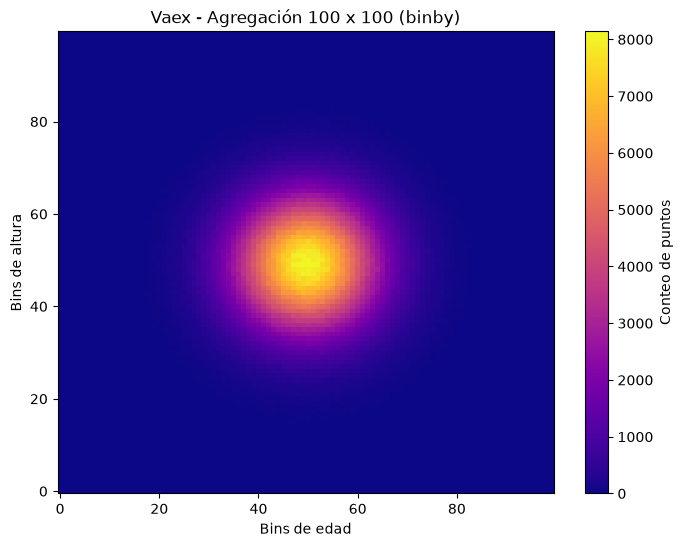

In [7]:
plt.figure(figsize=(8, 6))
plt.imshow(array_vaex, origin="lower", aspect="auto", cmap="plasma")
plt.title("Vaex - Agregación 100 x 100 (binby)")
plt.xlabel("Bins de edad")
plt.ylabel("Bins de altura")
plt.colorbar(label="Conteo de puntos")

plt.savefig("../resultados/graficos/vaex_100x100.png", dpi=300, bbox_inches="tight")
plt.show()

In [8]:
pd.DataFrame(array_vaex).to_csv("../resultados/tablas/vaex_100x100.csv", index=False)
print("Matriz resultante guardada en ../resultados/tablas/vaex_100x100.csv")

Matriz resultante guardada en ../resultados/tablas/vaex_100x100.csv
